#### Objectives
1. Provide the learner some more practice forexploratory data analysis.
2. Equip the learner to fit and evaluate a linear regression model.

In [118]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder

In [96]:
# Load the data from “cereal.csv” and plot histograms of sugar and vitamin content across different cereals.
cereals_df = pd.read_csv('./files/cereal.csv')
cereals_df

,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6,280,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8,135,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5,320,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0,330,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8,-1,25,3,1.0,0.75,34.384843
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,Triples,G,C,110,2,1,250,0.0,21.0,3,60,25,3,1.0,0.75,39.106174
73,Trix,G,C,110,1,1,140,0.0,13.0,12,25,25,2,1.0,1.00,27.753301
74,Wheat Chex,R,C,100,3,1,230,3.0,17.0,3,115,25,1,1.0,0.67,49.787445
75,Wheaties,G,C,100,3,1,200,3.0,17.0,3,110,25,1,1.0,1.00,51.592193


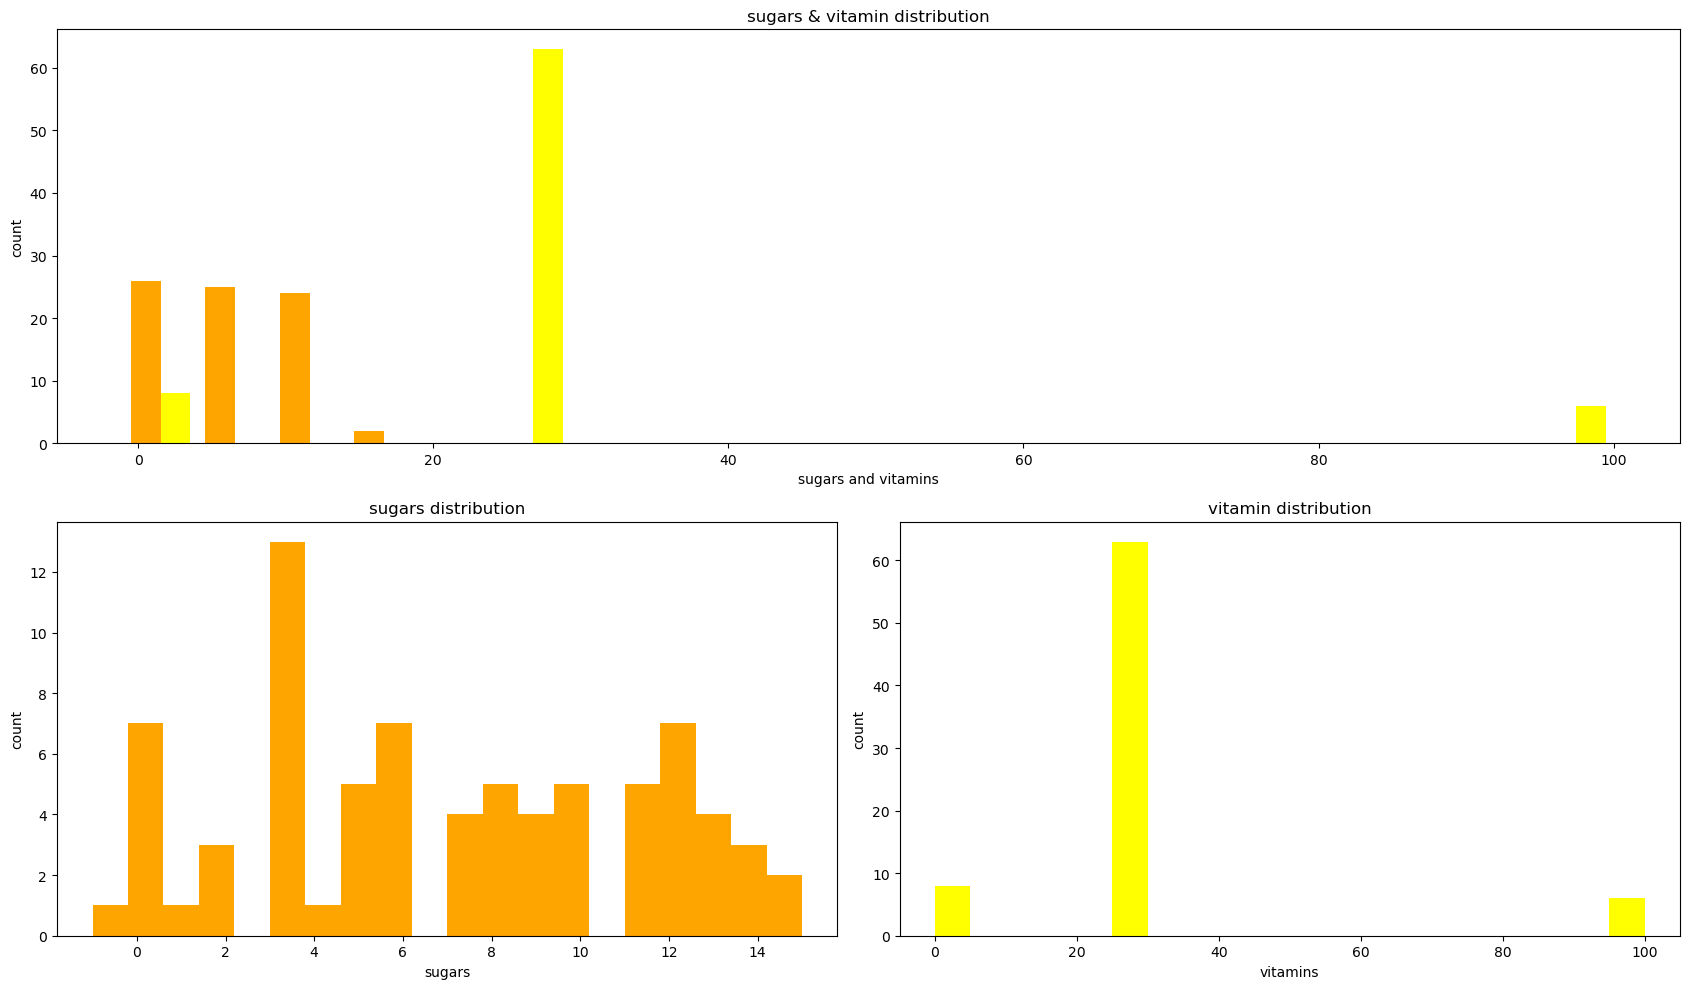

In [97]:
fig = plt.figure(figsize=(17,10))
plot = fig.add_gridspec(2,2)

ax1 = fig.add_subplot(plot[0,:])
ax1.hist([cereals_df['sugars'],cereals_df['vitamins']],color=['orange','yellow'],bins=20)
ax1.set_xlabel('sugars and vitamins')
ax1.set_ylabel('count')
ax1.set_title("sugars & vitamin distribution")

ax2 = fig.add_subplot(plot[1,0])
ax2.hist(cereals_df['sugars'],color='orange',bins=20)
ax2.set_xlabel('sugars')
ax2.set_ylabel('count')
ax2.set_title("sugars distribution")

ax3 = fig.add_subplot(plot[1,1])
ax3.hist(cereals_df['vitamins'],color='yellow',bins=20)
ax3.set_xlabel('vitamins')
ax3.set_ylabel('count')
ax3.set_title("vitamin distribution")

plt.tight_layout()
plt.show()

In [98]:
# The names of the manufactures are coded using alphabets, create a new column with their fullname using the below mapping.
manufacturer = {'N': 'Nabisco','Q': 'Quaker Oats','K': 'Kelloggs','R': 'Raslston Purina','G': 'General Mills' ,'P' :'Post' ,'A':'American Home Foods Products'}
cereals_df['manufacturer'] = cereals_df['mfr'].map(manufacturer)

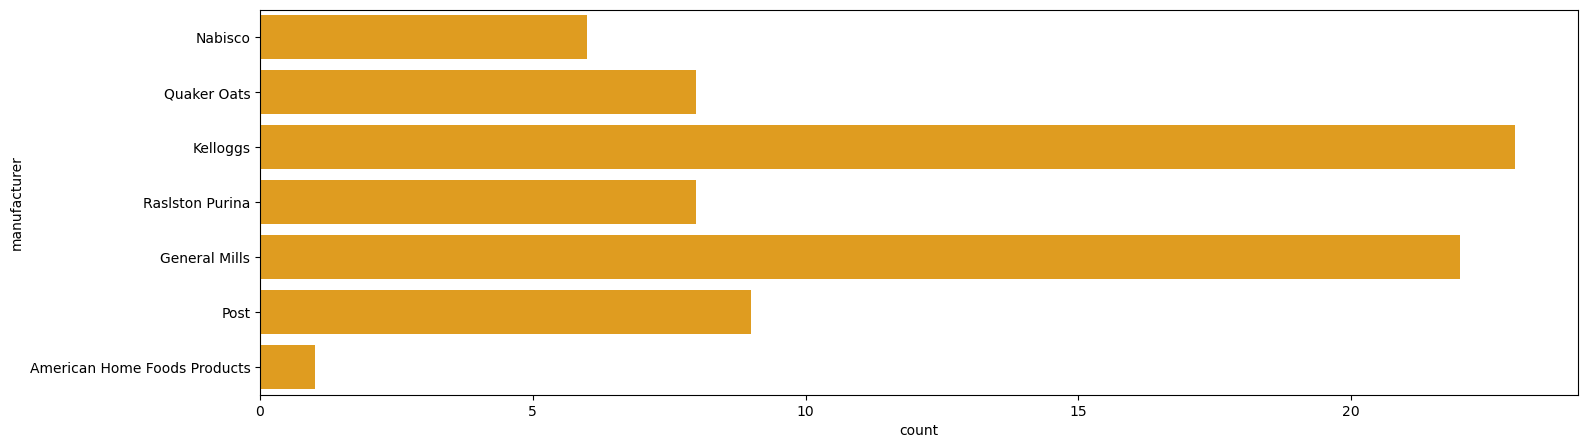

In [99]:
# Create a bar plot where each manufacturer is on the y axis and the height of the bars depict the number of cereals manufactured by them.
plt.figure(figsize=(17,5))
sns.countplot(cereals_df['manufacturer'],color='orange')
plt.show()

In [111]:
# Extract the rating as your target variable ‘y’ and all numerical parameters as your predictors ‘x’. Separate 25% of your data as test set
cereals_df['type']= LabelEncoder().fit_transform(cereals_df['type'])
cereals_df['mfr']= LabelEncoder().fit_transform(cereals_df['mfr'])
x,y = cereals_df.iloc[:,1:16],cereals_df['rating']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,train_size=0.75,random_state=42)

In [112]:
# Fit a linear regression module and measure the mean squared error on test dataset
lm = LinearRegression()
lm.fit(x_train,y_train)
y_pred = lm.predict(x_test)

1.533545599749647e-28

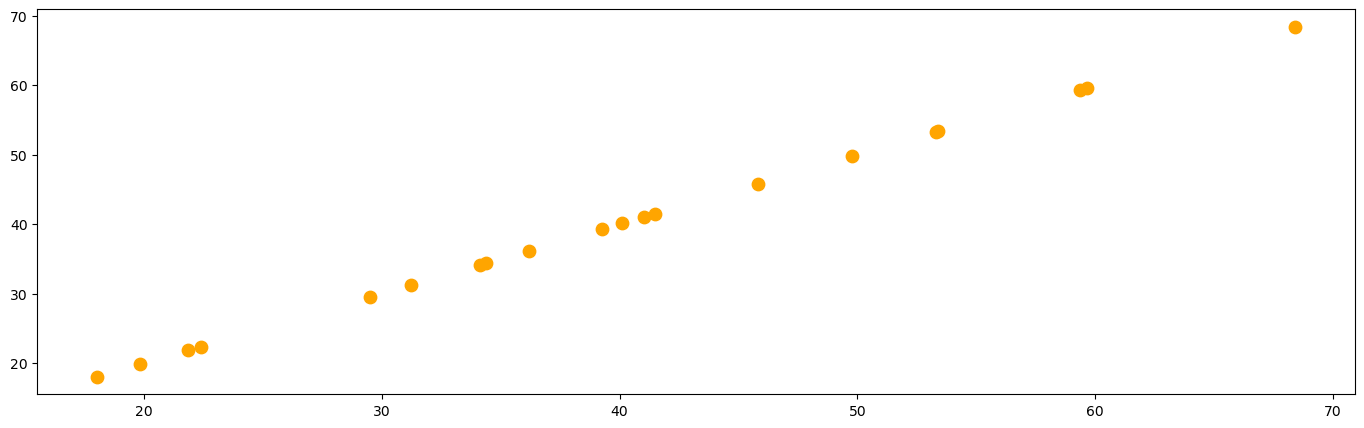

1.533545599749647e-28

In [122]:
plt.figure(figsize=(17,5))
plt.scatter(y_test,y_pred,color='orange',s=80)
plt.show()
mean_squared_error(y_test,y_pred)